<a href="https://colab.research.google.com/github/kpmunoz09/DeepLearning/blob/main/Sanabria_Maria_Munoz_Karen_DLSem7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##**Momento 2. Reconstrucción de imágenes con Autoencoder**

###Implementación de un Autoencoder para reconstrucción de imágenes usando MNIST.



### 1. Cargue y preparación de datos


In [1]:
from tensorflow.keras.datasets import mnist

# 1. Cargar el dataset MNIST desde Keras
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# 2. Convertir a float32 y normalizar los píxeles dividiendo entre 255.0
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


La normalización es importante en los modelos de entrenamiento porque evita que características con rangos numéricos muy altos dominen el aprendizaje sobre otras. Asimismo, es clave para el descenso de gradiente, ya que previene oscilaciones bruscas (efecto rebote) y logra que la superficie de pérdida sea más uniforme, permitiendo que el modelo avance hacia el mínimo global de manera más rápida y estable.


In [2]:
# Aplanar las imágenes de 28x28 a vectores unidimensionales de 784 elementos
x_train = x_train.reshape((len(x_train), 784))
x_test = x_test.reshape((len(x_test), 784))

Transformar una imagen en un vector significa desarmar la estructura espacial en forma de cuadrícula (2D: 28*28) y alinear todos sus píxeles uno detrás de otro formando una sola fila larga (1D: 784).

### 2. Construcción del Autoencoder

In [3]:
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import Dense

# 1. Definir dimensiones
input_dim = 784       # Dimensión de entrada (28x28 píxeles aplanados)
latent_dim = 64       # Dimensión del espacio latente (cuello de botella)

# 2. Construir el Encoder (Codificador)
input_layer = Input(shape=(input_dim,))
encoded = Dense(128, activation="relu")(input_layer)  # Capa intermedia de compresión
latent_space = Dense(latent_dim, activation="relu")(encoded) # Espacio latente comprimido

# 3. Construir el Decoder (Decodificador)
decoded_intermediate = Dense(128, activation="relu")(latent_space)
output_layer = Dense(input_dim, activation="sigmoid")(decoded_intermediate) # Salida reconstruida (mismo tamaño que la entrada)

# 4. Unir todo en el modelo completo del Autoencoder
autoencoder = Model(inputs=input_layer, outputs=output_layer)

#### * Por qué la última capa usa sigmoide.

##### Se usa sigmoide en la última capa debido a que cuando se normalizaron los datos obtuvimos valores en un rango de 0.0 hasta 1.0 para las imágenes del dataset. La función Sigmoide toma cualquier valor que entregue la red neuronal y lo convierte en un numero que esté en el rango entre 0.0 y 1.0 lo cual garantiza que la salida del modelo tenga exactamente la misma escala que las imágenes originales que está intentando reconstruir.
#### * Qué significa que el espacio latente sea más pequeño que la entrada.

##### Al tener una dimensión del espacio latente más pequeña que la entrada significa que tenemos un "cuello de botella", lo que implica que para este ejercicio, la imágen inicial del dataset que es de 784 pixeles ahora se guardará en un espacio de 64, esto permite a la red perder información secundaria que luego tendrá que reconstruir por medio del decodificador. Lo anterior permite que la red no aprenda de memoria y aprenda patrones estructurales.

### 3. Compilación del modelo

In [4]:
# Compilar el modelo con Adam y la función de pérdida MSE
autoencoder.compile(optimizer="adam", loss="mse")

# Mostrar resumen de la arquitectura
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 218,192 (852.31 KB)

 Trainable params: 218,192 (852.31 KB)

 Non-trainable params: 0 (0.00 B)

##### **MSE** es la métrica que nos permite saber cual es el promedio de los errores que comete el modelo cuando se entrena para reconstruir una imágen, es decir, que tan diferente es la imagen resultante de la imágen original.

### 4. Entrenamiento

In [5]:
# Entrenar el Autoencoder utilizando x_train tanto como entrada como objetivo
history = autoencoder.fit(
    x_train, x_train,
    epochs=20,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)


Epoch 1/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 0.0560 - val_loss: 0.0282
Epoch 2/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0223 - val_loss: 0.0174
Epoch 3/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 0.0159 - val_loss: 0.0139
Epoch 4/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0132 - val_loss: 0.0120
Epoch 5/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0116 - val_loss: 0.0106
Epoch 6/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0105 - val_loss: 0.0096
Epoch 7/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0096 - val_loss: 0.0090
Epoch 8/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0090 - val_loss: 0.0085
Epoch 9/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0085 - val_loss: 0.0080
Epoch 10/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.0080 - val_loss: 0.0075
Epoch 11/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.0076 - val_loss: 0.0072
Epoch 12/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 

#### ¿por qué la entrada y la salida son iguales?:
##### Se usa x_train como entrada y salida debido a que en un modelo de aprendizaje no supervisado no hay etiquetas, es decir, no hay una clasificación para los valores del data set sino que la tarea del modelo es reconstruir el valor de la entrada con lo que aprendió buscando la menor diferencia posible.

### 5. Visualización
#### Comparaciones visuales.

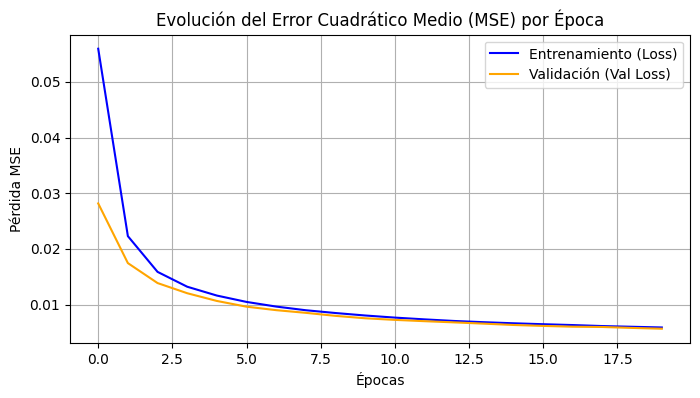

In [17]:
import matplotlib.pyplot as plt

# 1. GRAFICAR LA PÉRDIDA (LOSS)
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Entrenamiento (Loss)', color='blue')
plt.plot(history.history['val_loss'], label='Validación (Val Loss)', color='orange')
plt.title('Evolución del Error Cuadrático Medio (MSE) por Época')
plt.xlabel('Épocas')
plt.ylabel('Pérdida MSE')
plt.legend()
plt.grid(True)
plt.show()


Imágenes Originales vs Reconstruidas
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


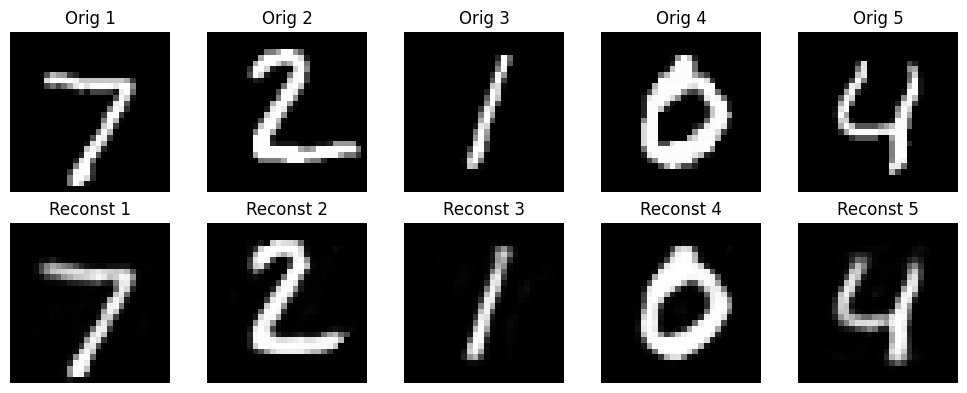

In [20]:
# 2. MOSTRAR 5 IMÁGENES ORIGINALES VS RECONSTRUIDAS
print("Imágenes Originales vs Reconstruidas")
n = 5
reconstructed_imgs = autoencoder.predict(x_test[:n])

# Como la salida está aplanada (784), se devuelve a formato 28x28 para poder dibujarla
reconstructed_imgs = reconstructed_imgs.reshape(-1, 28, 28)

plt.figure(figsize=(10, 4))
for i in range(n):
    # Fila superior: Imágenes Originales
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title(f"Orig {i+1}")
    plt.axis("off")

    # Fila inferior: Imágenes Reconstruidas
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(reconstructed_imgs[i], cmap='gray')
    plt.title(f"Reconst {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

####**Análisis:**

*   ¿Qué detalles se pierden?
##### Los detalles que se pierden en la imagen reconstruida respecto a la originar son detalles como los bordes, y el grosor del trazo.
*   ¿La reconstrucción es borrosa?
##### La reconstrucción de la imagen es borrosa debido a que la imagen en el proceso de entrenamiento pasa por el cuello de botella el cual borra detalles secundarios y descarta cierta información la cual al reconstruirla no es posible reescribirla con precisión sino que busca el menor riesgo de error poniendo valores intermedios.
*   ¿Qué pasa si reduces demasiado el espacio latente?
##### Si se reduce mucho el espacio latente se pierde la información relevante para la reconstrucción, las imágenes pasaran a ser solamente manchas pixeladas y el modelo no tendrá la información mínima para devolver la imagen.

#### Conclusiones:
##### El comportamiento de la función de perdida MSE en las épocas establecidas para el entrenamiento permite evidenciar una tendencia decreciente y constante hasta estabilizarse.
##### El optimizador Adam ajustó correctamente los pesos, se evidencia que no hubo sobreajuste y se obtuvo un modelo que reconstruye correctamente las entradas.
##### La reconstrucción de las imagenes de entrada en el modelo no son copias auténticas, sino que difieren en algunas características como los bordes y grosor de los trazos, esto debido a que el modelo en el espacio latente comprime la imagen tomando la información principal e ignorando información secundaria.